## Small model with post-FIC
## Imports

In [63]:
import numpy as np
from tvb.simulator.lab import *
from jr_models import wFICJansenRit, pFICJansenRit
import pyvista as pv
import matplotlib.pyplot as plt 
from scipy.spatial import cKDTree

## Parameters
##### variables
set1: y0=0.05, tau_d=1000, eta=0.001, gc_val=50, ring_graph(9)

In [114]:
your_y0_target = np.array([0.005])
your_eta = np.array([0.1])              # (default: 0.1)
your_tau_d = np.array([1000])             # (default: 50)

# global coupling value (G)
gc_val = np.array([100])                 # (default: 30)

#### connectivity

In [115]:
def plot_graph(points, adjacency):
    """
    Parameters
    ----------
    points: np.array (N,3) 
    lines: np.array (N,2)
    """

    P = pv.PolyData(points)
    A1 = adjacency > 0
    A2 = adjacency < 0

    lines1 = []
    lines2 = []
    for i in range(len(A1)):
        for j in range(i, len(A1)):
            if A1[i,j]:
                lines1 += [points[i], points[j]]
            if A2[i,j]:
                lines2 += [points[i], points[j]]
    lines1 = np.array(lines1)
    lines2 = np.array(lines2)

    p = pv.Plotter()
    p.add_mesh(P)
    if len(lines1) > 0:
        p.add_lines(lines1, color="green", width=0.05)
    if len(lines2) > 0:
        p.add_lines(lines2, color="red", width=0.01)

    return p

def plot_graph_activity(conn, time, data, dt=0.1, show_max=False):

    clim = [-np.max(np.abs(data)), np.max(np.abs(data))]

    p = pv.Plotter()

    def create_mesh(t):
        points = pv.PolyData(conn.centres)
        points["activity"] = data[int((t-time[0])/dt),:]
        p.add_mesh(points, point_size=10,render_points_as_spheres=True, clim=clim)

    p.add_slider_widget(create_mesh, [time[0], time[-1]], title="time [ms]")

    if show_max:
        # nodes with biggest spikes
        maxis = np.max(data, axis=0)
        indices = np.argsort(maxis)[-1]

        p.add_mesh(pv.PolyData(conn.centres[indices]), point_size=20)
        
    p.show()


def generate_ring_graph(N):
    # 1. Generate node positions on a unit circle
    angles = np.linspace(0, 2*np.pi, N, endpoint=False)

    x_coords = np.cos(angles)
    y_coords = np.sin(angles)
    z_coords = np.zeros_like(angles)

    centres = np.vstack((x_coords, y_coords, z_coords)).T
    labels  = np.array([f"{i}" for i in range(N)])

    # 2. Generate the adjacency matrix
    weights = np.zeros((N,N), dtype=int)

    for i in range(N):
        prev_node = (i - 1 + N) % N
        next_node = (i + 1) % N 

        weights[i, prev_node] = 1
        weights[i, next_node] = 1

    lengths = weights*10

    return centres, labels, weights, lengths

def generate_sphere_graph(N, k_neighbors=4):
    # 1. Generate node postions on a unit sphere
    centres = []
    golden_angle = np.pi * (3.0 - np.sqrt(5.0))

    for i in range(N):
        y      = 1 - (i / float(N))
        radius = np.sqrt(1 - y * y)
        theta  = i * golden_angle

        x = radius * np.cos(theta)
        z = radius * np.sin(theta)

        centres.append([x,y,z])

    centres = np.array(centres)
    labels  = np.array([f"{i}" for i in range(N)])

    # 2. Generate adjacency matrix by finding k-nearest neighbors
    tree = cKDTree(centres)

    weights = np.zeros((N,N), dtype=int)
    lengths = np.zeros((N,N), dtype=int)

    distances, indices = tree.query(centres, k=k_neighbors + 1)

    for i in range(N):
        for neighbor_index, dist in zip(indices[i], distances[i]):
            if i != neighbor_index:
                weights[i, neighbor_index] = 1
                weights[neighbor_index, i] = 1
                lengths[i, neighbor_index] = dist
                lengths[neighbor_index, i] = dist

    return centres, labels, weights, lengths

centres, labels, weights, lengths = generate_sphere_graph(50)
speed   = np.array([3])

plot_graph(centres, weights).show()

Widget(value='<iframe src="http://localhost:33135/index.html?ui=P_0x71520e5554d0_22&reconnect=auto" class="pyv…

## Utilities

In [116]:
def find_closest_value(input_value, muy_dict, shift=1):
    # Find the index of the closest value in FP_y0 to the input_value
    if input_value <= 0.0189 or (input_value > 0.079 and input_value < 0.097) or input_value >= 0.125:
        reg = 'FP' 
    elif input_value > 0.0189 and input_value < 0.065:
        reg = 'SLC'
    elif input_value >= 0.097 and input_value < 0.125:
        reg = 'FLC'
    mu_arr, y0_arr = muy_dict[reg]
    mu_arr = np.array(mu_arr)
    y0_arr = np.array(y0_arr)
    if input_value > np.max(y0_arr) or input_value < np.min(y0_arr) :
        #print('y0 input value > max or < min of the y0 array: setting mu to closest available value')
        closest_index = np.argmin(np.abs(y0_arr - input_value))
    else:
        closest_index = np.argmin(np.abs(y0_arr - input_value))
    # Get the corresponding value from FP_mu using the index
    try: 
        corresponding_value = mu_arr[closest_index+shift]
    except:
        corresponding_value = mu_arr[closest_index]
    #print(f'y0:{input_value} on {reg} -------> mu: {numpy.round(corresponding_value, 4)} idx ={closest_index}  !!!')
    return np.round(corresponding_value, 4)

def get_init_conds(input_value, FP_y0, FP_y1, FP_y2, FP_y3, FP_y4, FP_y5, shift=5):
    # Find the index of the closest value in FP_y0 to the input_value
    closest_index = np.argmin(np.abs(FP_y0 - input_value))
    # Get the corresponding value from state variables using the index + the shift
    #print(f'y0:{input_value} -------> idx: {closest_index+shift} !!!')
    try: 
        corresponding_values = [FP_y0[closest_index+shift], FP_y1[closest_index+shift], FP_y2[closest_index+shift],
         FP_y3[closest_index+shift],FP_y4[closest_index+shift],FP_y5[closest_index+shift]]
    except:
        corresponding_values = [FP_y0[closest_index], FP_y1[closest_index], FP_y2[closest_index],
         FP_y3[closest_index],FP_y4[closest_index],FP_y5[closest_index]]
    return np.round(corresponding_values, 4)

def get_initial_values(y0_target, s_conn, wFIC=True):
    # setting mu and y0_target
    mu_y0_dict = np.load("mu_y0_dict.npy", allow_pickle=True).item()
    mu_val = find_closest_value(y0_target, mu_y0_dict, 3)

    # loading state variabels to mu correspondence from file
    mu_values, y0s, y1s, y2s, y3s, y4s, y5s, _ = np.load("all_ys_vs_mu_array.npy", allow_pickle=True)

    init_y0 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[0], (1,1,s_conn.weights.shape[0],1))
    init_y1 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[1], (1,1,s_conn.weights.shape[0],1))
    init_y2 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[2], (1,1,s_conn.weights.shape[0],1))
    init_y3 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[3], (1,1,s_conn.weights.shape[0],1))
    init_y4 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[4], (1,1,s_conn.weights.shape[0],1))
    init_y5 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[5], (1,1,s_conn.weights.shape[0],1))
    init_y0d = init_y0.copy()
    init_y2d = init_y2.copy()
    init_wFIC = np.random.uniform(1,1, size=(1,1,s_conn.weights.shape[0],1))
    
    if wFIC:
        fic_init_UNI =  np.stack([
            init_y0, init_y1, init_y2,
            init_y3, init_y4, init_y5,
            init_y0d, init_y2d, init_wFIC
        ], axis=1).squeeze(axis=2)
    else:
        fic_init_UNI = np.stack([
            init_y0, init_y1, init_y2,
            init_y3, init_y4, init_y5,
        ], axis=1).squeeze(axis=2)

    return mu_val, fic_init_UNI

def build_connectvitiy(weights, lengths, labels, centres, speed):
    s_conn = connectivity.Connectivity(
        weights = weights,
        tract_lengths= lengths,
    )

    s_conn.weights       = s_conn.weights - s_conn.weights*np.eye(s_conn.weights.shape[0])
    s_conn.weights       = s_conn.scaled_weights(mode='tract')
    s_conn.region_labels = labels
    s_conn.centres       = centres
    s_conn.speed         = speed

    s_conn.configure()

    return s_conn

## Simulation
#### Run functions

In [117]:
def run_wfic_sim(stimulations = [([0], 0, 180000)], integration="det"):
    '''defines the separate runction to run the simulation with the model defined above
    input: parameter'''

    s_conn            = build_connectvitiy(weights, lengths, labels, centres, speed)
    mu_val, init_vals = get_initial_values(your_y0_target, s_conn)
    N                 = s_conn.number_of_regions

    jrm_fic = wFICJansenRit(
        v0        = np.array([6.]), 
        eta       = your_eta,
        y0_target = your_y0_target,
        tau_d     = your_tau_d
    )
    
    if integration == 'det':
        your_integrator = integrators.HeunDeterministic(dt=0.1)

        
    if integration == 'stoch':
        sigma         = np.zeros(9) 
        sigma[3]      = 0.00000025
        your_integrator = integrators.HeunStochastic(dt=0.1, noise=noise.Additive(nsig=sigma))

        
    sim = simulator.Simulator(
        connectivity       = s_conn,
        model              = jrm_fic,
        coupling           = coupling.SigmoidalJansenRit(a=gc_val,r=np.array([0.56])),
        integrator         = your_integrator,
        monitors           = [monitors.SubSample(period=1)],
        initial_conditions = init_vals,
        simulation_length  = 10000
    )
    
    sim.model.mu = np.array([mu_val])
    sim.configure()

    # run the 'pFIC' simulation
    y0    = np.zeros(shape=(0,N))
    y1    = np.zeros(shape=(0,N))
    y2    = np.zeros(shape=(0,N))
    wFIC = np.zeros(shape=(0,N))

    for stim in stimulations:
        targs, val, t = stim
        mu = mu_val if val==0 else val
        print("mu = ", mu)

        # update simulation parameters
        sim.simulation_length = t
        sim.model.mu = np.ones(N)*mu_val
        sim.model.mu[targs] = mu

        # run section
        output = sim.run()
        
        ssamp = output[0][1]
        y0   = np.vstack([y0, ssamp[:,0,:,0]])
        y1   = np.vstack([y1, ssamp[:,1,:,0]])
        y2   = np.vstack([y2, ssamp[:,2,:,0]])
        wFIC = np.vstack([wFIC, ssamp[:,3,:,0]])

    PSP = y1 - wFIC*y2
    
    return PSP,  wFIC, y0


def run_pfic_sim(pFIC = 1, stimulations = [([0], 0, 4000)], integration="stoch"):
    '''defines the separate runction to run the simulation with the model defined above
    input: parameter'''

    s_conn            = build_connectvitiy(weights, lengths, labels, centres, speed)
    mu_val, init_vals = get_initial_values(your_y0_target, s_conn, wFIC=False)
    N                 = s_conn.number_of_regions

    jrm_fic = pFICJansenRit(
        v0   = np.array([6.]), 
        pFIC = pFIC,
    )
    
    if integration == 'det':
        your_integrator = integrators.HeunDeterministic(dt=0.1)

        
    if integration == 'stoch':
        sigma         = np.zeros(6) 
        sigma[3]      = 0.00000025
        your_integrator = integrators.HeunStochastic(dt=0.1, noise=noise.Additive(nsig=sigma))

        
    sim = simulator.Simulator(
        connectivity       = s_conn,
        model              = jrm_fic,
        coupling           = coupling.SigmoidalJansenRit(a=gc_val,r=np.array([0.56])),
        integrator         = your_integrator,
        monitors           = [monitors.SubSample(period=1)],
        initial_conditions = init_vals,
        simulation_length  = 1000,  # default value, doesn't matter
    )
    
    sim.model.mu = np.array([mu_val])
    sim.configure()

    # run the 'pFIC' simulation
    y0 = np.zeros(shape=(0,N))
    y1 = np.zeros(shape=(0,N))
    y2 = np.zeros(shape=(0,N))

    for stim in stimulations:
        targs, val, t = stim
        mu = mu_val if val==0 else val
        print("mu = ", mu)

        # update simulation parameters
        sim.simulation_length = t
        sim.model.mu = np.ones(N)*mu_val
        sim.model.mu[targs] = mu

        # run section
        output = sim.run()
        
        ssamp = output[0][1]
        y0 = np.vstack([y0, ssamp[:,0,:,0]])
        y1 = np.vstack([y1, ssamp[:,1,:,0]])
        y2 = np.vstack([y2, ssamp[:,2,:,0]])

    PSP = y1 - pFIC*y2
    
    return PSP, y0, y1, y2

#### FIC tuning

In [123]:
print("Running fic tuning ...")

stimulations = [([0], 0, 18000)]
stimulations = stimulation  = [([0], 0, 40000), ([4], 10, 100), ([0], 0, 1000)]

fic_results = run_wfic_sim(stimulations=stimulations, integration="det")

Running fic tuning ...
mu =  0.0614
2025-08-21 15:35:34,255 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration
mu =  10
2025-08-21 15:35:59,517 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration
mu =  0.0614
2025-08-21 15:35:59,588 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration


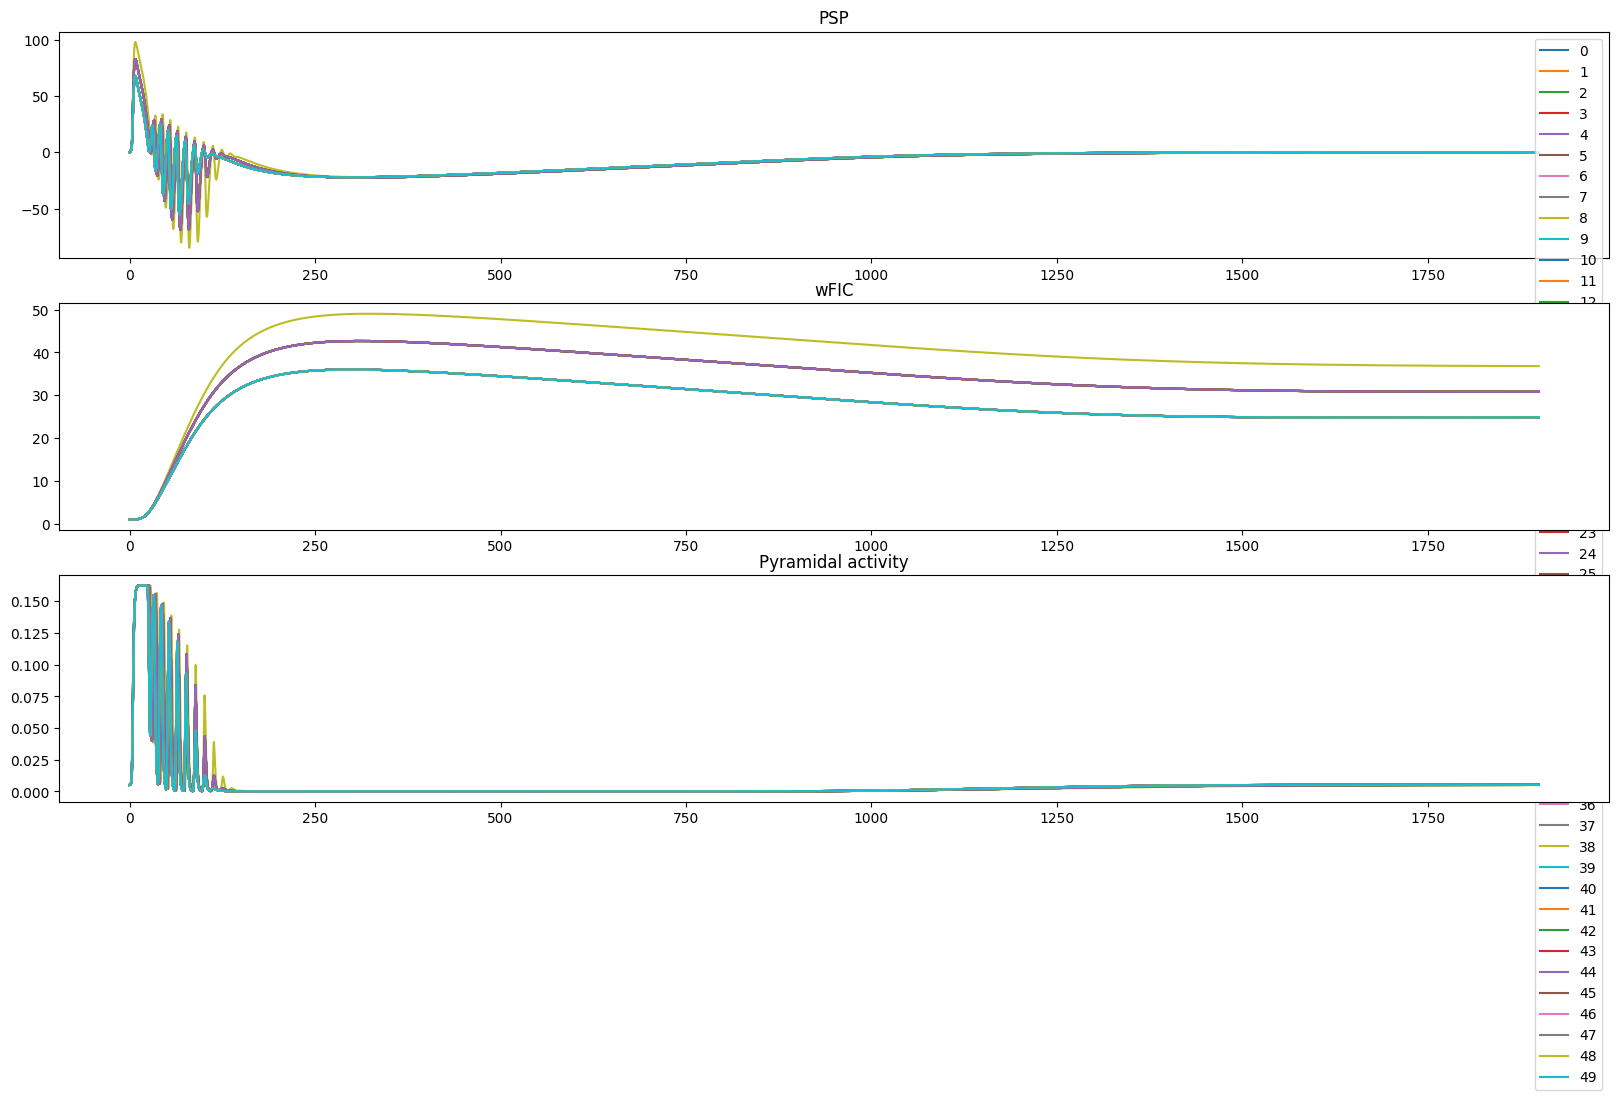

In [124]:
PSP, wFIC, y0 = fic_results
t = np.arange(PSP.shape[0])*0.1

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(20,10))
start = 0    # in [ms]
end   = 1900

s_idx = int(start*10)
e_idx = int(end*10)
axs[0].plot(t[s_idx:e_idx], PSP[s_idx:e_idx,:])
axs[0].set_title("PSP")
axs[0].legend(labels)

axs[1].plot(t[s_idx:e_idx], wFIC[s_idx:e_idx,:])
axs[1].set_title("wFIC")

axs[2].plot(t[s_idx:e_idx], y0[s_idx:e_idx,:])
axs[2].set_title("Pyramidal activity")

plt.show()

In [52]:
PSP[s_idx:e_idx,:].shape

(500, 9)

In [56]:
# rebuild connectivity
centres, labels, weights, lengths = generate_ring_graph(9)
lengths *= 10
speed    = np.array([3])
conn     = build_connectvitiy(weights, lengths, labels, centres, speed)

plot_graph_activity(conn, t[s_idx:e_idx], np.log(PSP[s_idx:e_idx, :]+1))

Widget(value='<iframe src="http://localhost:33135/index.html?ui=P_0x715214fa5190_13&reconnect=auto" class="pyv…

#### Post-FIC simulation

In [ ]:
print("Okkkkkkk let's goooo!")

pFIC         = np.mean(wFIC[-10:], axis=0)
stimulation  = [([0], 0, 1000), ([4], 0.1, 30), ([0], 0, 1000)]
#stimulation  = [([0], 0, 2000)]

pFIC_results = run_pfic_sim(pFIC=np.array([1]), stimulations=stimulation, integration="det")

Okkkkkkk let's goooo!
mu =  0.0614
2025-08-21 14:00:17,001 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration
mu =  0.1
2025-08-21 14:00:17,416 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration
mu =  0.0614
2025-08-21 14:00:17,429 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration


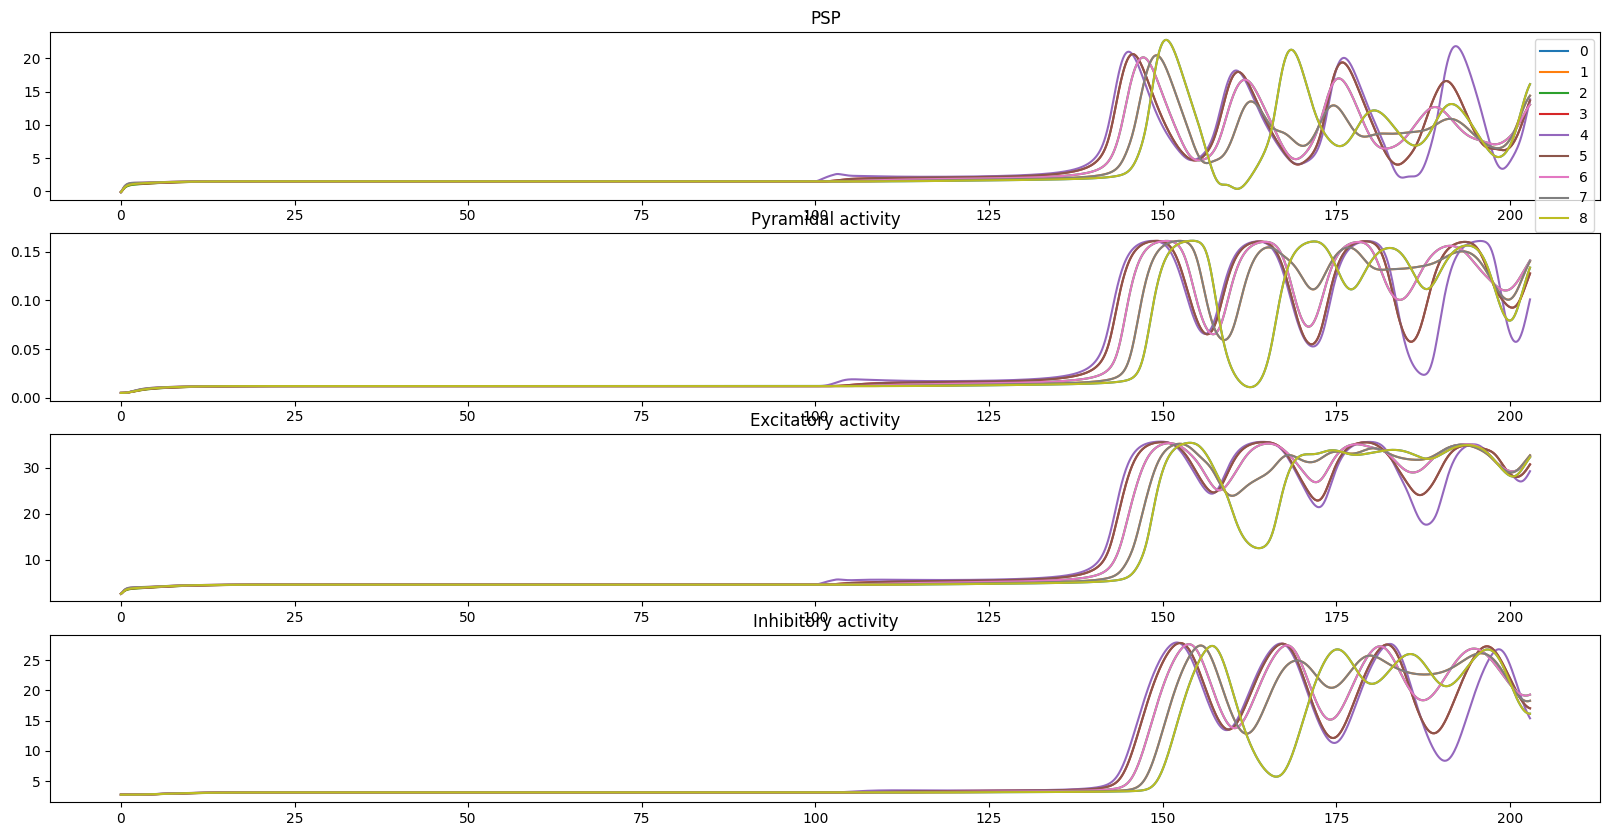

In [16]:
PSP, y0, y1, y2 = pFIC_results
t = np.arange(PSP.shape[0])*0.1

fig, axs = plt.subplots(nrows=4, ncols=1, figsize=(20,10))

axs[0].plot(t, PSP)
axs[0].set_title("PSP")
axs[0].legend(labels)

axs[1].plot(t, y0)
axs[1].set_title("Pyramidal activity")

axs[2].plot(t, y1)
axs[2].set_title("Excitatory activity")

axs[3].plot(t, y2)
axs[3].set_title("Inhibitory activity")

plt.show()